In [ ]:
from typing import Final
import numpy as np
import statistics
from numpy.typing import NDArray
from pyochain import Iter, Some, NONE
from collections.abc import Iterable

In [ ]:
SEED: int = 0
INSPECTION_PROB: float = 0.05
"""Inspection probability per day."""

RNG = np.random.default_rng(SEED)

def _single_inspection(draw: float) -> int:
    """Exercise `1.1`."""
    inspected = may_inspect(draw)
    branched = 1 if inspected else 0
    assert branched == int(inspected)
    return branched

def may_inspect(draw: float, prob: float = INSPECTION_PROB) -> bool:
    return draw < prob

_single_inspection(RNG.uniform())

0

In [ ]:
DAYS_NB: int = 70

# NOTE: I'm still not sure if the for loop was for the sum calculation in itself, the array creation, or both?
def manual_sum(draws: Iterable[float]) -> int:
    """Exercise `1.2`."""

    count = 0
    for d in draws:
        count += may_inspect(d)
    return count

# This is strictly equivalent to the manual sum and avoid the intermediate array, in case the for loop was only for the elements creation
_ = sum((may_inspect(RNG.uniform()) for _ in range(DAYS_NB)))

manual_sum(np.array([RNG.uniform() for _ in range(DAYS_NB)]))

np.int64(4)

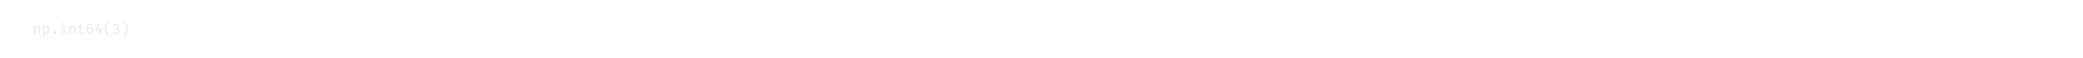

In [ ]:
def _pure_np() -> int:
    """Exercise `1.3`."""
    arr = RNG.uniform(size=DAYS_NB)
    pure_np = arr.__lt__(INSPECTION_PROB).sum()
    assert manual_sum(arr) == pure_np
    return pure_np

_pure_np()

In [ ]:
WORKING_DAYS_PER_MONTH: int = 21
FINE_AMOUNT: int = 100

# Named like that instead of `daysUntilChecked` to avoid issues with my linter (Ruff)7
def days_until_checked(prob: float = INSPECTION_PROB) -> int:
    """Exercise `1.4` + `1.5`."""
    d = 1
    while True:
        if may_inspect(RNG.uniform(), prob):
            return d
        else:
            d += 1

def _single_cycle_rate(days: int) -> float:
    return FINE_AMOUNT * WORKING_DAYS_PER_MONTH / days

d = days_until_checked()
print(f"Days until checked: {days_until_checked()}")
print(f"Single cycle rate: {_single_cycle_rate(d)}")

Days until checked: 33
Single cycle rate: 35.59322033898305


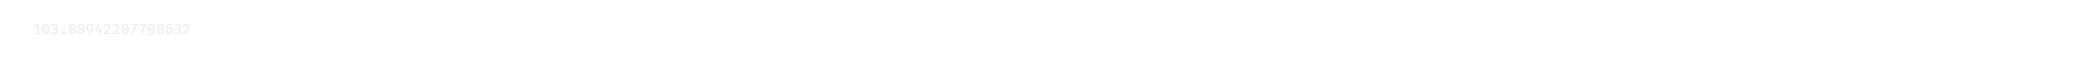

In [ ]:
# NOTE: I struggled a lot to understand some of the instructions phrases exact meaning trough the exercises.
# Notably `Call the function m = 10**4 times in a for loop`. I tought we were referencing a function named `m`, not the precedent function.
def _alternatives():
    """Not sure which way was wanted. Using my lib as another alternative example."""

    # `sum` can be swapped by an adapted version of the `manual_sum` function defined above
    _d1 = sum((days_until_checked() for _ in range(nb_calls))) / nb_calls

    # How I would do it normally.
    _d2 = (
        # Infinite iterator
        Iter.from_fn(lambda: Some(days_until_checked()))
        # Take the first `nb_calls` elements
        .take(nb_calls)
        # pass the result to `statistics.mean` to compute the mean
        .pipe(statistics.mean)
    )

def long_run_monthly_fine(nb_calls: int = 10**4) -> float:
    """Exercise `1.6`."""
    # NOTE: As asked, we store the values, but replacing `[...]` by `(...)` is preferable to avoid an unneded intermediate list.
    values = [days_until_checked() for _ in range(nb_calls)]
    D = statistics.mean(values)
    return FINE_AMOUNT * WORKING_DAYS_PER_MONTH / D

long_run_monthly_fine()